# ✍️ Pandas — Niveau 2 : ADAPTER (dataset Olist)

> **Compétences visées**
> - **Référentiel WCS** (onglet *Vue semaines*, semaine pandas P6, niveau dominant **2 · Adapter**)
>   - **C2.5** Tableaux de données : DataFrames avec Python et pandas — niveau 2
>   - **C1.1** Identifier les usages possibles des données et en évaluer la qualité — niveau 2
>   - **C4.2** Visualisations descriptives : nuages, boîtes à moustache, histogrammes — niveau 2
> - **Référentiel Simplon** (niveau 6)
>   - **C8** Développer des règles de nettoyage de données — *travaillée partiellement* : repérage des manquants et des doublons, uniformisation des dates (le script versionné viendra en S50)
>   - **C16** Définir les représentations graphiques adaptées aux objectifs d'analyse
>
> **Niveau 2 · Adapter** : tu appliques à un nouveau contexte des méthodes **fournies**. Chaque mission te donne la méthode, un exemple sur d'autres données et du code à trous.

---
## 📨 Contexte

**Olist** est une place de marché brésilienne : des milliers de petits vendeurs y vendent leurs produits, Olist gère la vitrine, les paiements et la livraison. L'entreprise a publié l'historique de ses commandes de **septembre 2016 à octobre 2018** (≈ 100 000 commandes).

Mariana, responsable commerciale, prépare le comité de direction. Elle te demande une **première analyse** :
- comment évoluent les ventes dans le temps ?
- quelles catégories de produits et quelles régions rapportent le plus ?
- les **retards de livraison** pèsent-ils sur la satisfaction des clients ?

Elle n'est pas technique : elle attend des **chiffres fiables**, des **graphiques lisibles** et une **synthèse courte**.

## 🗂️ Les données (dossier `data_olist/`, à côté de ce notebook)

| Fichier | Une ligne = | Clés |
|---|---|---|
| `olist_orders_dataset.csv` | une commande (statut, dates d'achat, de livraison, date prévue) | `order_id`, `customer_id` |
| `olist_order_items_dataset.csv` | un **article** d'une commande (prix, frais de port) | `order_id`, `product_id` |
| `olist_customers_dataset.csv` | un client (ville, État) | `customer_id` |
| `olist_products_dataset.csv` | un produit (catégorie en portugais, dimensions) | `product_id` |
| `olist_order_reviews_dataset.csv` | un avis client (note de 1 à 5) | `order_id` |
| `product_category_name_translation.csv` | une catégorie (nom portugais → anglais) | `product_category_name` |

Les tables se relient par leurs **clés**, comme en SQL (S42). Une commande peut contenir **plusieurs articles**.

⚠️ N'ouvre pas et n'enregistre pas ces CSV avec Excel : il peut modifier les dates et les séparateurs.

## ⏱️ Déroulé de la journée

| Horaire | Mission | Durée |
|---|---|---|
| 9 h 00 | Lecture du brief + chargement | 20 min |
| 9 h 20 | Mission 1 — Auditer les tables | 70 min |
| 10 h 45 | Mission 2 — Construire la table `ventes` | 90 min |
| 13 h 30 | Mission 3 — Évolution des ventes | 50 min |
| 14 h 20 | Mission 4 — Catégories et régions | 50 min |
| 15 h 20 | Mission 5 — Livraison et satisfaction | 60 min |
| 16 h 20 | Mission 6 — Livrer | 40 min |

Les missions sont **dans l'ordre** : chacune utilise le résultat de la précédente. Si tu es en retard, termine d'abord les missions 1 et 2 : ce sont elles qui comptent le plus pour la suite (Power Query, puis le nettoyage en S50).

**Livrable** : ce notebook complété (code + commentaires) et le fichier de la mission 6.

## 0. Chargement des données (fourni)

Exécute la cellule. Tu dois voir 6 lignes, une par table.

In [715]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 20)

DOSSIER = Path("data_olist")
commandes = pd.read_csv(DOSSIER / "olist_orders_dataset.csv")
articles = pd.read_csv(DOSSIER / "olist_order_items_dataset.csv")
clients = pd.read_csv(DOSSIER / "olist_customers_dataset.csv")
produits = pd.read_csv(DOSSIER / "olist_products_dataset.csv")
avis = pd.read_csv(DOSSIER / "olist_order_reviews_dataset.csv")
traduction = pd.read_csv(DOSSIER / "product_category_name_translation.csv")

tables = {"commandes": commandes, "articles": articles, "clients": clients,
          "produits": produits, "avis": avis, "traduction": traduction}

for nom, table in tables.items():
    print(f"{nom:<11} {table.shape}")

commandes   (99441, 8)
articles    (112650, 7)
clients     (99441, 5)
produits    (32951, 9)
avis        (99224, 7)
traduction  (71, 2)


In [716]:
commandes.dtypes

order_id                         str
customer_id                      str
order_status                     str
order_purchase_timestamp         str
order_approved_at                str
order_delivered_carrier_date     str
order_delivered_customer_date    str
order_estimated_delivery_date    str
dtype: object

### 📘 Rappel : travailler avec des dates

Exemple sur des rendez-vous (pas sur Olist) :

```python
rdv = pd.DataFrame({"debut": ["2026-03-02 09:00", "2026-03-15 14:30"],
                    "fin":   ["2026-03-05 18:00", "2026-03-15 16:00"]})
rdv["debut"] = pd.to_datetime(rdv["debut"])      # texte → vraie date
rdv["fin"] = pd.to_datetime(rdv["fin"])

rdv["duree"] = rdv["fin"] - rdv["debut"]         # une soustraction donne une durée
rdv["duree"].dt.days                             # → la durée en jours entiers
rdv["debut"].dt.to_period("M")                   # → le mois "2026-03", idéal pour grouper
rdv["debut"].dt.normalize()                      # → la date ramenée à minuit (compare au jour près)
rdv["debut"] > rdv["fin"]                        # les dates se comparent comme des nombres
```

Tant qu'une colonne est en texte (`object` ou `str`), aucun de ces calculs ne fonctionne : `pd.to_datetime` vient toujours en premier.

In [717]:
rdv = pd.DataFrame({"debut": ["2026-03-02 09:00", "2026-03-15 14:30"],
                    "fin":   ["2026-03-05 18:00", "2026-03-15 16:00"]})
rdv["debut"] = pd.to_datetime(rdv["debut"])      # texte → vraie date
rdv["fin"] = pd.to_datetime(rdv["fin"])

rdv["duree"] = rdv["fin"] - rdv["debut"]         # une soustraction donne une durée
rdv["duree"].dt.days                             # → la durée en jours entiers
rdv["debut"].dt.to_period("M")                   # → le mois "2026-03", idéal pour grouper
rdv["debut"].dt.normalize()                      # → la date ramenée à minuit (compare au jour près)
rdv["debut"] > rdv["fin"]
rdv

,debut,fin,duree
0,2026-03-02 09:00:00,2026-03-05 18:00:00,3 days 09:00:00
1,2026-03-15 14:30:00,2026-03-15 16:00:00,0 days 01:30:00


### 📘 Rappel : contrôler une jointure

Avec plusieurs tables, le danger n'est pas l'erreur Python, c'est le **chiffre faux sans message** : une jointure peut multiplier des lignes ou en perdre en silence.

| Pour… | Outil |
|---|---|
| comparer le nombre de lignes avant / après | `len(table)` |
| compter des identifiants différents | `.nunique()` |
| repérer une clé en double | `.duplicated(subset=["col"])`, `.is_unique` |
| garder les lignes dont la clé est dans une liste | `.isin(...)` |
| faire échouer une jointure qui dupliquerait des lignes | `merge(..., validate="many_to_one")` |
| ne garder qu'une ligne par clé | `.drop_duplicates(subset=["col"], keep=...)` |

**Équivalences SQL** : `merge(how="inner")` = `INNER JOIN`, `merge(how="left")` = `LEFT JOIN`.

---
## Mission 1 — Auditer les tables *(70 min)*

**Objectif** : dire à Mariana si les données sont fiables, **avant** tout calcul.

**Méthode** (une étape = une cellule)
1. Construire le tableau d'audit **par le code**, avec une boucle sur le dictionnaire `tables`.
2. Compter les commandes par statut.
3. Expliquer les dates de livraison vides en les croisant avec le statut.
4. Convertir les 5 colonnes de dates de `commandes` et afficher la période couverte.
5. Vérifier que `order_id` est unique dans `commandes` et dans `avis`.

📘 **Exemple** (sur le Titanic) : une ligne d'audit pour **une** table.
```python
ligne = {"table": "titanic", "lignes": len(titanic), "colonnes": titanic.shape[1],
         "cellules_vides": titanic.isna().sum().sum(), "doublons": titanic.duplicated().sum()}
```
À toi d'adapter : une ligne par table d'Olist, dans une boucle.

In [718]:
# Exemple pour les duplicates

DF = pd.DataFrame({
    'Nom': ['Alice', 'Bob', 'Alice', 'Charlie', 'Bob'],
    'Age': [25, 30, 25, 35, 30],
    'Ville': ['Paris', 'Lyon', 'Paris', 'Lille', 'Lyon']
})

lignes_identiques = DF[DF.duplicated(keep=False)]
print(lignes_identiques)

liste_lignes_identiques = lignes_identiques.values.tolist()
print(liste_lignes_identiques)

index_doublons = DF.index[DF.duplicated(keep=False)].tolist()
print(index_doublons)

     Nom  Age  Ville
0  Alice   25  Paris
1    Bob   30   Lyon
2  Alice   25  Paris
4    Bob   30   Lyon
[['Alice', 25, 'Paris'], ['Bob', 30, 'Lyon'], ['Alice', 25, 'Paris'], ['Bob', 30, 'Lyon']]
[0, 1, 2, 4]


In [719]:
# 1.1 — Tableau d'audit, construit par le code (aucun chiffre tapé à la main)
lignes_audit = []
for nom, table in tables.items():
    lignes_audit.append({
        "table": nom,
        "lignes": table.shape[0],           # nombre de lignes
        "colonnes": table.shape[1],         # nombre de colonnes
        "cellules_vides": table.isna().sum().sum(),   # total des cellules vides de la table
        "doublons": table.duplicated().sum(),         # lignes entièrement identiques
    })
audit = pd.DataFrame(lignes_audit)
audit

,table,lignes,colonnes,cellules_vides,doublons
0,commandes,99441,8,4908,0
1,articles,112650,7,0,0
2,clients,99441,5,0,0
3,produits,32951,9,2448,0
4,avis,99224,7,145903,0
5,traduction,71,2,0,0


In [720]:
# 1.2 — Répartition des commandes par statut
tables["commandes"]["order_status"].value_counts()

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

In [721]:
# Exemple de tableau de contingence (pd.crosstab)

DF = pd.DataFrame({
    'Sexe': ['Homme', 'Homme', 'Homme', 'Homme', 'Homme',
             'Femme', 'Femme', 'Femme', 'Femme', 'Femme'],
    'Boisson': ['Café', 'Café', 'Café', 'Thé', 'Thé',
                'Café', 'Thé', 'Thé', 'Thé', 'Thé']
})

tableau = pd.crosstab(DF['Sexe'], DF['Boisson'], margins=True)
print(tableau)

Boisson  Café  Thé  All
Sexe                   
Femme       1    4    5
Homme       3    2    5
All         4    6   10


In [722]:
# Liste de toutes les colonnes de toutes les tables
for nom, table in tables.items():
    print(nom, list(table.columns))

commandes ['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date']
articles ['order_id', 'order_item_id', 'product_id', 'seller_id', 'shipping_limit_date', 'price', 'freight_value']
clients ['customer_id', 'customer_unique_id', 'customer_zip_code_prefix', 'customer_city', 'customer_state']
produits ['product_id', 'product_category_name', 'product_name_lenght', 'product_description_lenght', 'product_photos_qty', 'product_weight_g', 'product_length_cm', 'product_height_cm', 'product_width_cm']
avis ['review_id', 'order_id', 'review_score', 'review_comment_title', 'review_comment_message', 'review_creation_date', 'review_answer_timestamp']
traduction ['product_category_name', 'product_category_name_english']


In [723]:
commandes.dtypes

order_id                         str
customer_id                      str
order_status                     str
order_purchase_timestamp         str
order_approved_at                str
order_delivered_carrier_date     str
order_delivered_customer_date    str
order_estimated_delivery_date    str
dtype: object

In [724]:
# 1.3 — Pourquoi des dates de livraison vides ?
# Croise le statut avec "la date de livraison est vide" (True / False)
pd.crosstab(commandes["order_status"], ~commandes["order_delivered_customer_date"].isna())

# Réponse : Le commandes ayant un status "Canceled, en cours, indisponible ..." 
#           ont une date de livraison "vide" ce qui semble logique. 

order_delivered_customer_date,False,True
order_status,,
approved,2,0
canceled,619,6
created,5,0
delivered,8,96470
invoiced,314,0
processing,301,0
shipped,1107,0
unavailable,609,0


In [725]:
# 1.4 — Convertir les dates, puis afficher la période couverte
colonnes_dates = ["order_purchase_timestamp", "order_approved_at",
                  "order_delivered_carrier_date", "order_delivered_customer_date",
                  "order_estimated_delivery_date"]

for col in colonnes_dates:
    commandes[col] = pd.to_datetime(commandes[col])

# On initialise des dates min et max
date_debut = commandes['order_estimated_delivery_date'].min()
date_fin   = commandes['order_delivered_customer_date'].max()

# On parcourt toute les colonnes pour chercher le min et max de toute la période
for col in colonnes_dates:
    if commandes[col].min() < date_debut:
            date_debut = commandes[col].min()
    if date_fin < commandes[col].max():
            date_fin = commandes[col].max()

print(commandes.dtypes)
print(f"Première commande : {date_debut.strftime('%d/%m/%Y')}")
print(f"Dernière commande : {date_fin.strftime('%d/%m/%Y')}")

order_id                                    str
customer_id                                 str
order_status                                str
order_purchase_timestamp         datetime64[us]
order_approved_at                datetime64[us]
order_delivered_carrier_date     datetime64[us]
order_delivered_customer_date    datetime64[us]
order_estimated_delivery_date    datetime64[us]
dtype: object
Première commande : 04/09/2016
Dernière commande : 12/11/2018


In [726]:
# 1.5 — Les clés sont-elles uniques ?
print(f"order_id unique dans commandes : {commandes["order_id"].is_unique}")
print(f"order_id unique dans commandes : {commandes["order_id"].nunique()}")
print(f"order_id unique dans avis      : {avis["order_id"].is_unique}")
print(f"order_id en double dans avis   : {avis["order_id"].duplicated().sum()}")

order_id unique dans commandes : True
order_id unique dans commandes : 99441
order_id unique dans avis      : False
order_id en double dans avis   : 551


✅ **Je vérifie**
- [ ] Le tableau d'audit a 6 lignes, et aucun chiffre n'est tapé à la main.
- [ ] `commandes.dtypes` affiche `datetime64` pour les 5 colonnes de dates.
- [ ] Je sais combien de commandes sont livrées (repère : **96 478**).

**Commentaire de la mission 1** *(3 à 5 phrases, complète les amorces)*

- Les six tables contiennent des nombres différentes de colonnes ; aucune ligne(s) entièrement en double.
- Les cellules vides se concentrent dans les tables "commandes", "produits" et "avis.
- Dans `commandes`, les dates de livraison manquent surtout pour les statuts "canceled", "invoiced", "processing", "shipped" et "unavailable" , parce que les commandes n'ont pas encore été livrées.
- Les données couvrent la période du 04/09/2016 au 12/11/2019.
- À surveiller pour la suite : dans `avis`, 551 commandes ont plusieurs avis, il faudra vérifier s'il s'agit des mêmes clients et voir si les avis sont des doublons, dans quel cas on nettoiera la colonne.

---
## Mission 2 — Construire la table d'analyse *(90 min)*

**Objectif** : une seule table `ventes`, avec **une ligne par article vendu** dans une commande **livrée**. Colonnes minimales : `order_id`, `order_purchase_timestamp`, `customer_state`, `categorie` (en anglais), `price`, `freight_value`, `montant`.

**Méthode** (l'ordre est imposé)
1. Filtrer `commandes` sur le statut `delivered` → `livrees`.
2. Partir de `articles` et ne garder que les articles des commandes livrées → `articles_livres`. **Son nombre de lignes est ta référence** : `ventes` devra avoir exactement le même.
3. Ajouter les informations, une jointure à la fois : `livrees` (date d'achat, `customer_id`) → `clients` (État) → `produits` (catégorie en portugais) → `traduction` (catégorie en anglais).
4. Créer `categorie` : le nom anglais, sinon le nom portugais, sinon `"unknown"`.
5. Créer `montant` = `price` + `freight_value`.
6. Prouver par le code que rien n'a été perdu ni dupliqué.

**Pourquoi `how="left"` ?** On part des articles et on ne veut en perdre **aucun**, même quand une information manque dans l'autre table (comme un `LEFT JOIN` en SQL).
**Pourquoi `validate="many_to_one"` ?** Plusieurs articles peuvent pointer vers le même client ou produit (*many*), mais chaque client ou produit n'apparaît qu'une fois dans sa table (*one*). Si ce n'est pas le cas, pandas s'arrête au lieu de dupliquer en silence.

📘 **Exemple** (une boutique, pas Olist) :
```python
lignes = pd.DataFrame({"ticket": [1, 1, 2], "produit": ["P1", "P2", "P9"], "prix": [3.0, 5.0, 2.0]})
catalogue = pd.DataFrame({"produit": ["P1", "P2"], "rayon": ["boulangerie", None]})

res = lignes.merge(catalogue, on="produit", how="left", validate="many_to_one")
len(res) == len(lignes)                          # True : rien perdu, rien dupliqué
res["rayon"] = res["rayon"].fillna("inconnu")    # P2 (rayon vide) et P9 (absent du catalogue)
```

In [727]:
# 2.1 — Commandes livrées et articles de référence
livrees = commandes[commandes.order_status == 'delivered']
articles_livres = articles[articles["order_id"].isin(livrees.order_id)]

print("Commandes livrées                :", len(livrees))
print("Articles à retrouver dans ventes :", len(articles_livres))

Commandes livrées                : 96478
Articles à retrouver dans ventes : 110197


In [728]:
for nom, table in tables.items():
    print(f'{nom:10}\t\t\t{table.shape}')
print(f'livrees\t\t\t\t{livrees.shape}')
print(f'articles_livres\t\t\t{articles_livres.shape}')

commandes 			(99441, 8)
articles  			(112650, 7)
clients   			(99441, 5)
produits  			(32951, 9)
avis      			(99224, 7)
traduction			(71, 2)
livrees				(96478, 8)
articles_livres			(110197, 7)


In [729]:
# 2.2 — Jointures successives (une par instruction, pour pouvoir contrôler)
ventes = articles_livres.merge(livrees[["order_id", "customer_id", "order_purchase_timestamp"]],
                               on="order_id", how="left", validate="many_to_one")
print("après livrees    :", len(ventes), ventes.shape[1])

ventes = ventes.merge(clients[["customer_id", "customer_state"]],
                      on="customer_id", how="left", validate="many_to_one")
print("après clients    :", len(ventes), ventes.shape[1])

ventes = ventes.merge(produits[["product_id", "product_category_name"]],
                      on="product_id", how = "left", validate="many_to_one")
print("après produits   :", len(ventes), ventes.shape[1])

ventes = ventes.merge(traduction, on="product_category_name", how = "left", validate="many_to_one")
print("après traduction :", len(ventes), ventes.shape[1])

après livrees    : 110197 9
après clients    : 110197 10
après produits   : 110197 11
après traduction : 110197 12


In [730]:
# 2.3 — Une catégorie lisible pour chaque ligne, puis le montant
print("Sans catégorie (portugais) :", ventes["product_category_name"].isna().sum())
print("Sans traduction (anglais)  :", ventes["product_category_name_english"].isna().sum())

ventes["categorie"] = ventes["product_category_name_english"].fillna(ventes["product_category_name"]).fillna("Inconnu")
ventes["montant"] = ventes["price"] + ventes["freight_value"]

Sans catégorie (portugais) : 1537
Sans traduction (anglais)  : 1559


In [731]:
# 2.4 — Contrôles chiffrés : chaque ligne doit afficher True
print("Aucun article perdu ni dupliqué  :", len(ventes) == len(articles_livres))
print("Toutes les commandes livrées     :", ventes["order_id"].nunique() == 96478)
print("Aucune catégorie vide            :", ventes["categorie"].isna().sum() == 0)
print("Aucun État vide                  :", ventes["customer_state"].isna().sum() == 0) ### QUEL ETAT ???

Aucun article perdu ni dupliqué  : True
Toutes les commandes livrées     : True
Aucune catégorie vide            : True
Aucun État vide                  : True


✅ **Je vérifie**
- [ ] **96 478** commandes livrées et **110 197** lignes dans `ventes`.
- [ ] Les 4 contrôles de la cellule 2.4 affichent `True`.
- [ ] Si une jointure lève une `MergeError`, je ne retire pas `validate` : je cherche la clé en double.

**Commentaire de la mission 2** *(3 à 5 phrases, complète les amorces)*

- Je suis parti de la table `commandes` et des commandes ayant un statut "Livrée", car une ligne de `ventes` correspond à une vente livrée.
- Pour les jointures, j'ai choisi `left` parce qu'on veut conserver nos commandes livrées et y ajouter les informations correspondants des tables `clients` puis `produits` puis `traduction`.
- Mes contrôles prouvent que `ventes` contient 110 197 lignes, autant que le nombre de commandes livrées.
- 1537 lignes n'avaient pas de catégorie et 1539 pas de traduction : je les ai remplacées par "Inconnu".

---
## Mission 3 — Évolution des ventes dans le temps *(50 min)*

**Objectif** : montrer à Mariana comment évoluent les ventes, mois par mois.

**Méthode**
1. Créer une colonne `mois` à partir de la date d'achat.
2. Par mois : chiffre d'affaires (somme des `montant`), nombre de **commandes** (pas d'articles !) et panier moyen = CA ÷ nombre de commandes.
3. Compter les commandes par mois dans la table `commandes` **complète** (avant le filtre `delivered`).
4. Écarter les mois incomplets. **Règle proposée** : un mois est incomplet s'il compte moins de 500 commandes dans la table complète. Tu peux choisir un autre seuil si tu le justifies.
5. Tracer la courbe du CA des mois gardés, avec un titre et des axes nommés.
6. Trouver le mois record et proposer une explication.

📘 **Exemple** : compter des commandes, pas des lignes.
```python
tickets = pd.DataFrame({"mois": ["01", "01", "01", "02"],
                        "ticket": [1, 1, 2, 3], "montant": [3, 5, 2, 10]})
tickets.groupby("mois").agg(ca=("montant", "sum"), nb_tickets=("ticket", "nunique"))
# janvier : ca = 10 et nb_tickets = 2 (et non 3 : le ticket 1 a deux lignes)
```

In [732]:
ventes['montant'].sum()

np.float64(15419773.75)

In [733]:
# 3.1 — Indicateurs par mois
ventes["mois"] = ventes["order_purchase_timestamp"].dt.to_period("M")
mensuel = ventes.groupby("mois").agg(
    ca=("montant", "sum"),
    nb_commandes=("order_id", "nunique"),   # Nombre de commandes
    nb_articles=("order_id", "count")       # Nombre d'articles
)
mensuel["panier_moyen"] = (mensuel["ca"] / mensuel["nb_commandes"]).round(2)
mensuel

,ca,nb_commandes,nb_articles,panier_moyen
mois,,,,
2016-09,143.46,1,3,143.46
2016-10,46490.66,265,313,175.44
2016-12,19.62,1,1,19.62
2017-01,127482.37,750,913,169.98
2017-02,271239.32,1653,1858,164.09
2017-03,414330.95,2546,2897,162.74
2017-04,390812.40,2303,2569,169.70
2017-05,566851.40,3546,4004,159.86
2017-06,490050.37,3135,3489,156.32


In [734]:
# 3.2 — Commandes par mois dans la table complète (tous statuts)
commandes_par_mois = commandes.groupby(commandes["order_purchase_timestamp"].dt.to_period("M")).size()
commandes_par_mois

order_purchase_timestamp
2016-09       4
2016-10     324
2016-12       1
2017-01     800
2017-02    1780
2017-03    2682
2017-04    2404
2017-05    3700
2017-06    3245
2017-07    4026
2017-08    4331
2017-09    4285
2017-10    4631
2017-11    7544
2017-12    5673
2018-01    7269
2018-02    6728
2018-03    7211
2018-04    6939
2018-05    6873
2018-06    6167
2018-07    6292
2018-08    6512
2018-09      16
2018-10       4
Freq: M, dtype: int64

In [735]:
# 3.3 — Garder les mois complets
SEUIL = 500   # règle proposée : à ajuster et justifier
mois_complets = commandes_par_mois[commandes_par_mois >= SEUIL].index
mensuel_complet = mensuel[mensuel.index.isin(mois_complets)]

print("Mois écartés :", list(mensuel.index.difference(mois_complets).astype(str)))
print("CA total (tous mois)    :", round(mensuel["ca"].sum()), "R$")
print("CA total (mois complets):", round(mensuel_complet["ca"].sum()), "R$")

Mois écartés : ['2016-09', '2016-10', '2016-12']
CA total (tous mois)    : 15419774 R$
CA total (mois complets): 15373120 R$


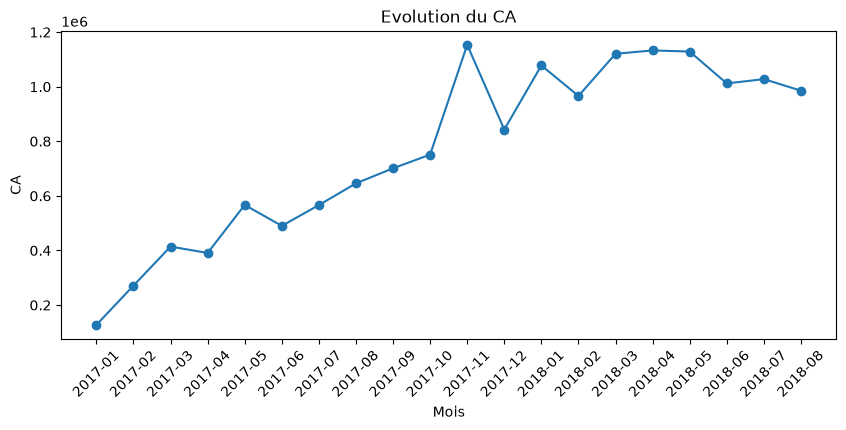

In [736]:
# 3.4 — Courbe du CA mensuel
# Objectif du graphique (C16) : montrer une … (évolution ? comparaison ? distribution ?)
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(mensuel_complet.index.astype(str), mensuel_complet["ca"], marker="o")
ax.set_title("Evolution du CA")
ax.set_xlabel("Mois")
ax.set_ylabel("CA")
ax.tick_params(axis="x", rotation=45)
plt.show()

In [737]:
# 3.5 — Mois record
print(f'Mois record    : {mensuel_complet["ca"].idxmax()}') # Novembre
print(f'Montant record : {mensuel_complet["ca"].max()}')    # Montant

Mois record    : 2017-11
Montant record : 1153364.2


✅ **Je vérifie**
- [ ] CA total, tous mois confondus : environ **15,4 millions de R$**.
- [ ] Panier moyen des mois complets entre **145 et 170 R$**. Autour de 140 R$ ? Tu as divisé par des articles au lieu de commandes.
- [ ] Ma courbe a un titre, deux axes nommés et l'unité (R$).
- 💡 Pour le mois record, pense à ce qui se passe fin novembre dans le commerce en ligne.

**Commentaire de la mission 3** *(3 à 5 phrases, complète les amorces)*

- J'ai écarté les mois septembre, octobre et décembre 2016 , parce que la table complète n'y compte que 1, 265 et 1 commandes.
- Sur la période gardée, le CA mensuel passe de 127 482 R$ à 985 491 R$.
- Le mois record est novembre 2017 avec 1 153 364 R$, sans doute à cause des commandes pour Noël.
- Le panier moyen reste autour de 150 R$ : la croissance vient donc surtout du Nombres de commandes.

---
## Mission 4 — Catégories et régions *(50 min)*

**Objectif** : montrer où se concentre le chiffre d'affaires.

**Méthode**
1. CA par catégorie, trié du plus grand au plus petit.
2. Part de chaque catégorie en % du CA total ; vérifier que la somme fait 100 %.
3. Top 10 des catégories et graphique en barres horizontales.
4. Par État : CA, nombre de commandes (`nunique`) et part du CA.
5. Part du CA réalisée par l'État n°1.

📘 **Exemple** : calculer une part.
```python
ventes_rayon = pd.Series({"boulangerie": 600, "épicerie": 300, "boissons": 100})
part = ventes_rayon / ventes_rayon.sum() * 100    # 60 %, 30 %, 10 %
part.sum()                                        # 100.0
```

In [738]:
# 4.1 — CA et part par catégorie
ca_categorie = ventes.groupby("categorie")["montant"].sum().sort_values(ascending=False)
part_categorie = 100 * (ca_categorie / ventes["montant"].sum()).round(3)

print("Somme des parts :", round(part_categorie.sum(), 0), "%")
top10 = pd.DataFrame({"ca": ca_categorie.head(10).round(0),
                      "part_pct": part_categorie.head(10).round(2)})

print(f'Somme de 10 catégories du TOP10 : {top10.part_pct.sum():.2f} %')
top10

Somme des parts : 100.0 %
Somme de 10 catégories du TOP10 : 62.40 %


,ca,part_pct
categorie,,
health_beauty,1412090.0,9.2
watches_gifts,1264333.0,8.2
bed_bath_table,1225209.0,7.9
sports_leisure,1118257.0,7.3
computers_accessories,1032724.0,6.7
furniture_decor,880330.0,5.7
housewares,758392.0,4.9
cool_stuff,691681.0,4.5
auto,669455.0,4.3


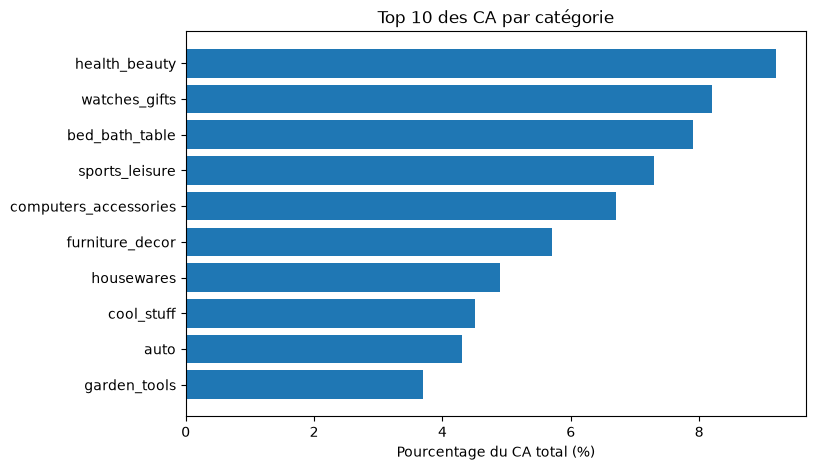

In [739]:
# 4.2 — Graphique du top 10
# Objectif du graphique (C16) : …
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top10.index, top10["part_pct"])
ax.invert_yaxis()   # la première catégorie en haut
ax.set_title("Top 10 des CA par catégorie")
ax.set_xlabel("Pourcentage du CA total (%)")
plt.show()

In [740]:
etats["ca"].sum()

np.float64(15419773.75)

In [741]:
# 4.3 — CA, commandes et part par État
etats = ventes.groupby("customer_state").agg(
    ca=("montant", 'sum'),
    nb_commandes=("order_id", "nunique"),
).sort_values("ca", ascending=False)
etats["part_pct"] = 100 * (etats["ca"] / etats["ca"].sum()).round(3)
etats.head(10)
etats

,ca,nb_commandes,part_pct
customer_state,,,
SP,5769703.15,40501,37.4
RJ,2055401.57,12350,13.3
MG,1818891.67,11354,11.8
RS,861472.79,5345,5.6
PR,781708.80,4923,5.1
SC,595127.78,3546,3.9
BA,591137.81,3256,3.8
DF,346123.35,2080,2.2
GO,334212.35,1957,2.2


In [742]:
# 4.4 — Part du CA réalisée par l'État n°1
print(f"Part du CA réalisé par l'état {etats['part_pct'].idxmax()} : {etats['part_pct'].max():.1f} %")

Part du CA réalisé par l'état SP : 37.4 %


✅ **Je vérifie**
- [ ] La somme des parts des catégories affiche **100 %**.
- [ ] Le nombre de commandes par État est compté avec `nunique`, pas avec `count`.
- [ ] Les 10 premières catégories pèsent un peu plus de 60 % du CA.

**Commentaire de la mission 4** *(3 à 5 phrases, complète les amorces)*

- Les 10 premières catégories représentent 62.4 % % du CA ; les trois premières sont "health_beauty, "watches_gifts" et "bed_bath_table".
- L'État de "SP" réalise à lui seul 37.4% % du CA, suivi de RJ avec 13.3%.
- L'activité est donc très concentrée, parce que 3 états concentrent 50 % des ventes.
- Mariana devrait concentrer ses efforts sur les catégories et les états concentrant les ventes.

---
## Mission 5 — Livraison et satisfaction *(60 min)*

**Objectif** : vérifier si les retards de livraison font baisser les notes des clients.

**Règle de retard** : une commande est en retard si elle est reçue **un jour calendaire après** la date prévue, ou plus tard. Reçue le jour prévu, quelle que soit l'heure : elle est à l'heure. D'où `.dt.normalize()` des deux côtés.

**Méthode**
1. Garder les commandes livrées **qui ont une date de réception** → `livraisons`.
2. Calculer le délai en jours (achat → réception) et l'indicateur `en_retard`.
3. Part de commandes en retard et délai médian.
4. Histogramme des délais.
5. Une seule note par commande : choisir **une** des deux règles fournies (A ou B) et la justifier.
6. Note moyenne en retard / à l'heure.

📘 **Exemple** : la moyenne d'une colonne de `True`/`False` donne une proportion.
```python
s = pd.Series([True, False, False, True])
s.mean() * 100    # 50.0 → 50 % de True
```

In [743]:
# 5.1 — Délai et retard
# livraisons = livrees.dropna(subset=[...]).copy()
# livraisons["delai_jours"] = (... - ...).dt.days
# livraisons["en_retard"] = (livraisons["order_delivered_customer_date"].dt.normalize()
#                            > ...)

livraisons = livrees.dropna(subset=["order_delivered_customer_date"]).copy()
livraisons["delai_jours"] = (livrees["order_delivered_customer_date"] - livrees["order_approved_at"]).dt.days
livraisons["en_retard"] = (livraisons["order_delivered_customer_date"].dt.normalize()
                           > livraisons["order_estimated_delivery_date"].dt.normalize())

print("Commandes avec date de réception :", len(livraisons))
print(f"Part en retard                   : {(100 * livraisons["en_retard"].sum()) / len(livraisons):.2f} %")
print(f"Délai médian                     : {livraisons["delai_jours"].median():.1f} jours")

print(f'Min : {livraisons["delai_jours"].min()} \t\t\t Max : {livraisons["delai_jours"].max()}')

Commandes avec date de réception : 96470
Part en retard                   : 6.77 %
Délai médian                     : 9.0 jours
Min : -7.0 			 Max : 208.0


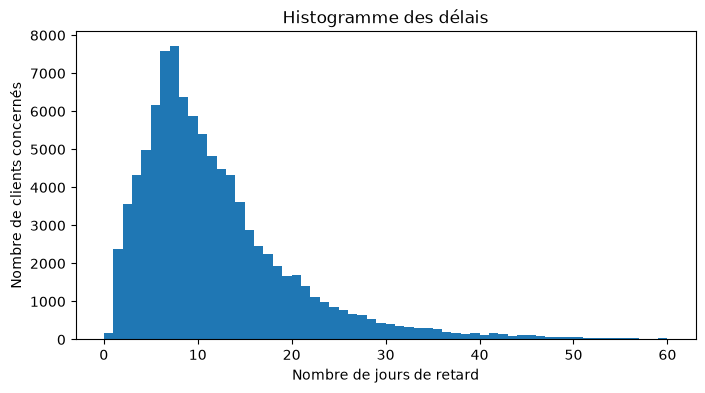

In [744]:
# 5.2 — Histogramme des délais (C4.2)
# Objectif du graphique (C16) : …
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(livraisons["delai_jours"], bins=range(0, 61))
ax.set_title("Histogramme des délais")
ax.set_xlabel("Nombre de jours de retard")
ax.set_ylabel("Nombre de clients concernés")
plt.show()

In [745]:
# 5.3 — Une seule note par commande : garde UNE des deux règles

# Règle A — le dernier avis rédigé
avis["review_answer_timestamp"] = pd.to_datetime(avis["review_answer_timestamp"])
# note_commande = (avis.sort_values("review_answer_timestamp")
#                      .drop_duplicates(subset=["order_id"], keep='first')
#                      [["order_id", "review_score"]])

# Règle B — la moyenne des avis de la commande (décommente pour l'utiliser)
note_commande = avis.groupby("order_id", as_index=False)["review_score"].mean()

print("Une ligne par commande :", note_commande["order_id"].is_unique)
# note_commande

Une ligne par commande : True


In [746]:
# 5.4 — Note moyenne selon le retard
livraisons_notes = livraisons.merge(note_commande, on="order_id", how="left", validate="one_to_one")
print("Commandes sans avis :", livraisons_notes["review_score"].isna().sum())

livraisons_notes.groupby("en_retard")["review_score"].mean().round(2)

Commandes sans avis : 646


en_retard
False    4.29
True     2.27
Name: review_score, dtype: float64

✅ **Je vérifie**
- [ ] **96 470** commandes livrées ont une date de réception.
- [ ] `note_commande["order_id"].is_unique` affiche `True`.
- [ ] Environ 650 commandes n'ont aucun avis : elles ne comptent pas dans la note moyenne.

**Commentaire de la mission 5** *(3 à 5 phrases, complète les amorces)*

- 6.7 % des commandes livrées arrivent en retard ; le délai médian est de 9 jours.
- Note moyenne : 2.3 en retard, contre 4.3 à l'heure.
- Pour les avis multiples, j'ai choisi la règle B, parce qu'elle fait une moyenne de tous les avis d'une même commande et ainsi tient compte de tous les avis.
- Limite de mon analyse : On ne tient compte que des délais pour l'anayse des notes des avis. On pourrait aussi choisir la règle A qui peut être également cohérente.

---
## Mission 6 — Livrer *(40 min)*

**Méthode**
1. Exporter la table `ventes` en **CSV** (obligatoire) et la relire en vérifiant les types.
2. Exporter en **Parquet** si `pyarrow` est installé (optionnel).
3. Rédiger la synthèse pour Mariana : chaque affirmation reprend un chiffre calculé plus haut.

💡 Un CSV ne garde pas les types : à la relecture, les dates redeviennent du texte. Il faut les reconvertir avec `parse_dates`. Le Parquet, lui, conserve les types.

In [747]:
# 6.1 — Export CSV (obligatoire) et relecture
colonnes = ["order_id", "order_purchase_timestamp", "mois", "customer_state",
            "categorie", "price", "freight_value", "montant"]
export = ventes[colonnes].copy()
export["mois"] = export["mois"].astype(str)
export.to_csv("ventes_olist.csv", index=False)

relu = pd.read_csv("ventes_olist.csv", parse_dates=[2])
print("Même nombre de lignes :", len(relu) == len(export))
print(relu.dtypes)

Même nombre de lignes : True
order_id                               str
order_purchase_timestamp               str
mois                        datetime64[us]
customer_state                         str
categorie                              str
price                              float64
freight_value                      float64
montant                            float64
dtype: object


In [748]:
# 6.2 — Export Parquet (optionnel, nécessite pyarrow : pip install pyarrow)
try:
    export.to_parquet("ventes_olist.parquet", index=False)
    relu_pq = pd.read_parquet("ventes_olist.parquet")
    print("Types conservés :", (relu_pq.dtypes == export.dtypes).all())
except ImportError:
    print("pyarrow absent : export Parquet ignoré, le CSV suffit.")

Types conservés : True


**Remarque :**

PyArrow est une bibliothèque Python qui implémente le format Apache Arrow. C'est stocké en binaire contrairement aux CSV où c'est stoké en texte.

Elle permet notamment :
- De manipuler des données en mémoire de manière efficace.
- De lire et écrire des fichiers Parquet.
- D'échanger des données entre différents outils (Pandas, Spark, etc.).
- D'améliorer les performances pour certains traitements de données.

Les avantages :
- Réduction de la taille du fichier.
- Lecture souvent plus rapide.
- Conservation des types de données (int, float, datetime, etc.).
- Possibilité de lire uniquement certaines colonnes.

### Synthèse pour Mariana
*(5 à 8 lignes, sans jargon technique, un chiffre par affirmation : complète les amorces)*

- **Ventes** : entre janvier 2017 et août 2018, le chiffre d'affaires mensuel est passé de 127 482 à 985 491 R$ ; record en novembre 2017 (1 153 364 R$), lié à la période de Noël.
- **Catégories** : les 10 premières font 62.4 % du CA, emmenées par les catégories "health_beauty, "watches_gifts" et "bed_bath_table".
- **Régions** : l'État de SP réalise à lui seul 37.4 % du CA.
- **Livraison** : 6.8 % des commandes arrivent en retard ; leur note moyenne est de 2.3 contre 4.3 à l'heure.
- **Recommandation** : La règle B, parce qu'elle fait la moyenne des avis d'une commande et de cette façon elle tient compte de tous les avis.

✅ **Avant de rendre**
- [ ] Menu *Noyau › Redémarrer et tout exécuter* : aucune cellule en erreur.
- [ ] Les 6 commentaires et la synthèse sont remplis, sans « … » restant.
- [ ] Le fichier `ventes_olist.csv` est à côté du notebook.

---
## 🚀 Pour aller plus loin (si tu as fini)

1. **Tranches de délai** : note moyenne par tranche.
   ```python
   livraisons_notes["tranche"] = pd.cut(livraisons_notes["delai_jours"], bins=[-1, 7, 14, 21, 30, 1000],
                                        labels=["0-7 j", "8-14 j", "15-21 j", "22-30 j", "> 30 j"])
   ```
2. **Répartition des notes** (1 à 5) en retard / à l'heure : `pd.crosstab(..., normalize="index")`.
3. **Boîte à moustaches** des délais pour les 5 premiers États (C4.2).
4. **Frais de port** : leur part dans le montant, par État.
5. **Clients fidèles** : `customer_unique_id` identifie une personne, `customer_id` une commande. Les clients reviennent-ils ?
6. **Retards par État** : croise les missions 4 et 5.

In [749]:
# 1. Tranches de délai
livraisons_notes["tranche"] = pd.cut(livraisons_notes["delai_jours"], bins=[-1, 7, 14, 21, 30, 1000],
                                        labels=["0-7 j", "8-14 j", "15-21 j", "22-30 j", "> 30 j"])

In [750]:
# 2. Répartition des notes en fonction du retard (True / False)
pd.crosstab(livraisons_notes['review_score'], livraisons_notes['en_retard'], 
            normalize='index').round(2) * 100

en_retard,False,True
review_score,,
1.000000,63.0,37.0
1.500000,88.0,12.0
2.000000,81.0,19.0
2.500000,83.0,17.0
3.000000,91.0,9.0
3.333333,100.0,0.0
3.500000,96.0,4.0
4.000000,97.0,3.0
4.333333,100.0,0.0


In [751]:
# Jointure pour ajouter une colonne 'customer_state'
print(f'AVANT shape : {livraisons_notes.shape}')
livraisons_notes = livraisons_notes.merge(clients[["customer_id", "customer_state"]],
                      on="customer_id", how="left", validate="many_to_one")
print(f'APRES shape : {livraisons_notes.shape}')

AVANT shape : (96470, 12)
APRES shape : (96470, 13)


In [752]:
display(livraisons_notes[['customer_id', 'customer_state', 'delai_jours', 'en_retard', 'review_score', 'tranche']].sample(5))
livraisons_notes.describe()

,customer_id,customer_state,delai_jours,en_retard,review_score,tranche
37197,45ef11af1fdca65776516f93ce5d5cdd,SP,4.0,False,5.0,0-7 j
91039,86e22883736a519f6aeacb3be7ca3a31,SP,6.0,False,3.0,0-7 j
4895,5b222737a3a5874ff3162df1ee6ae5c2,MG,14.0,False,5.0,8-14 j
49508,4dee9f4481876294efc334d9b05045ce,SP,4.0,False,5.0,0-7 j
88936,98c84d8694eea067223f53975b06d47c,GO,9.0,False,5.0,8-14 j


,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,delai_jours,review_score
count,96470,96456,96469,96470,96470,96456.000000,95824.000000
mean,2018-01-01 23:17:43.624411,2018-01-02 10:41:38.246330,2018-01-05 04:46:44.911992,2018-01-14 12:41:33.581683,2018-01-25 16:58:03.644656,11.642459,4.156158
min,2016-09-15 12:16:38,2016-09-15 12:16:38,2016-10-08 10:34:01,2016-10-11 13:46:32,2016-10-04 00:00:00,-7.000000,1.000000
25%,2017-09-14 08:56:46.500000,2017-09-14 14:43:49,2017-09-18 16:42:10,2017-09-25 22:15:09.500000,2017-10-05 00:00:00,6.000000,4.000000
50%,2018-01-20 19:34:43.500000,2018-01-22 13:49:23.500000,2018-01-24 16:03:24,2018-02-02 19:32:21,2018-02-16 00:00:00,9.000000,5.000000
75%,2018-05-05 18:29:50.250000,2018-05-06 10:52:55.750000,2018-05-08 14:32:00,2018-05-15 22:54:48.500000,2018-05-28 00:00:00,15.000000,5.000000
max,2018-08-29 15:00:37,2018-08-29 15:10:26,2018-09-11 19:48:28,2018-10-17 13:22:46,2018-10-25 00:00:00,208.000000,5.000000
std,NaN,NaN,NaN,NaN,NaN,9.520355,1.283615


['SP', 'RJ', 'MG', 'RS', 'PR']


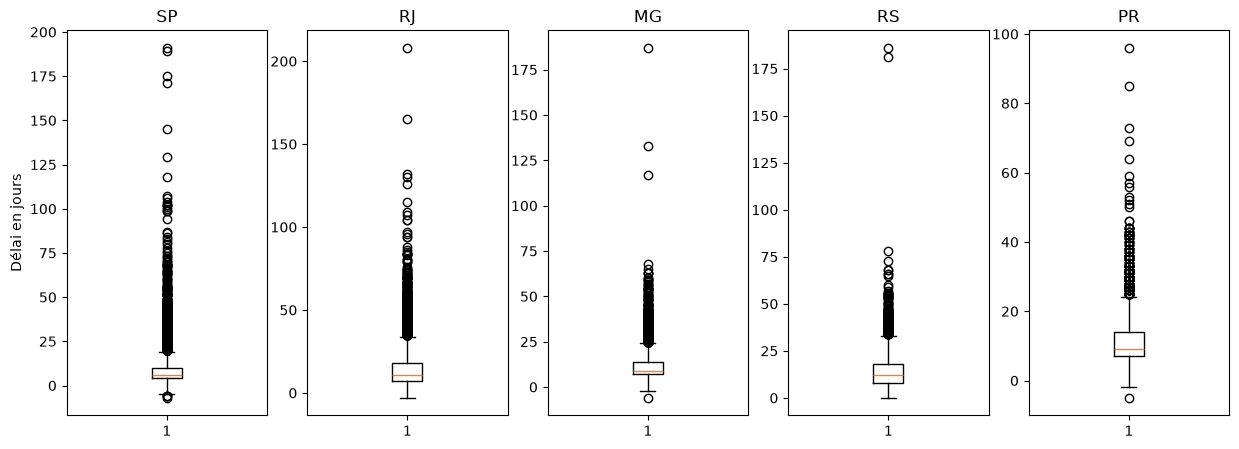

In [753]:
# 3. Boîte à moustaches des délais pour les 5 premiers États ()

# On sélectionne les 5 états principaux (en nombre de commandes)
top5_state = list(etats.index[:5])
print(top5_state)

fig, axes = plt.subplots(ncols=5, figsize=(15, 5))
axes[0].set_ylabel("Délai en jours")

# On affiche les 5 boites à moustaches
for i, state in enumerate(top5_state):
    data = livraisons_notes[livraisons_notes['customer_state'] == state]['delai_jours'].dropna()
    axes[i].boxplot(data, showfliers=True)
    axes[i].set_title(state)
plt.show()

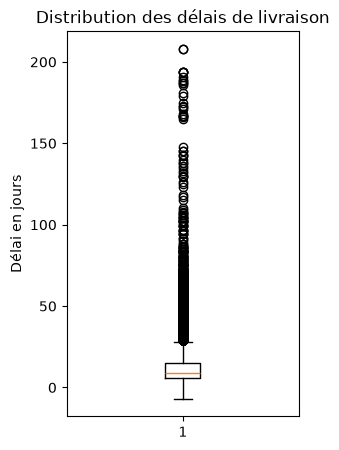

In [754]:
# Test avec une boite à moustache contenant tous les états
data = livraisons_notes['delai_jours'].dropna()
fig, ax = plt.subplots(figsize=(3, 5))
ax.boxplot(data, showfliers=True)
ax.set_title("Distribution des délais de livraison")
ax.set_ylabel("Délai en jours")
plt.show()

In [755]:
# 4. Frais de port : Leur part dans le montant par état
pct_frais_de_port = ventes.groupby('customer_state')[['montant', 'freight_value']].sum().sort_values(by='montant')

# Ajout de la colonne de porucentages
pct_frais_de_port['pct_frais_de_port'] = (100 * pct_frais_de_port['freight_value'] / pct_frais_de_port['montant']).round(2)
pct_frais_de_port

,montant,freight_value,pct_frais_de_port
customer_state,,,
RR,9039.52,1982.05,21.93
AP,16141.81,2767.00,17.14
AC,19575.33,3644.36,18.62
AM,27585.47,5429.63,19.68
RO,56966.00,11283.24,19.81
TO,60007.37,11604.86,19.34
SE,70289.13,13714.94,19.51
AL,94172.49,15316.77,16.26
RN,100714.78,18609.12,18.48


**Rearque** : On observe une tendance : "plus les frais de ports sont importants moins les clients achètent"

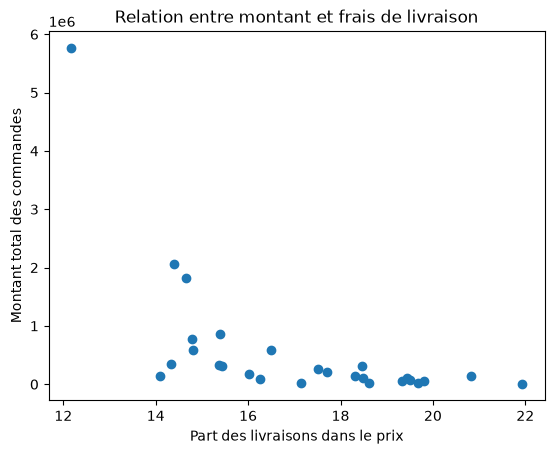

In [756]:
plt.scatter(pct_frais_de_port['pct_frais_de_port'], pct_frais_de_port['montant'])
plt.title("Relation entre montant et frais de livraison")
plt.ylabel("Montant total des commandes")
plt.xlabel("Part des livraisons dans le prix")
plt.show()

In [757]:
# 5. Les clients reviennent-ils ?

clients['customer_unique_id'].value_counts().value_counts().sort_index()

count
1     93099
2      2745
3       203
4        30
5         8
6         6
7         3
9         1
17        1
Name: count, dtype: int64

**Réponse** : Oui mais assez peu.
93099 clients n'ont commandé qu'une seule fois contre environ 3100 qui ont commandé plusieurs fois.

In [758]:
# On ajoute les notes des avis dans la dataframe 'etats'
etats['review_score'] = livraisons_notes.groupby('customer_state')['review_score'].mean().round(2)

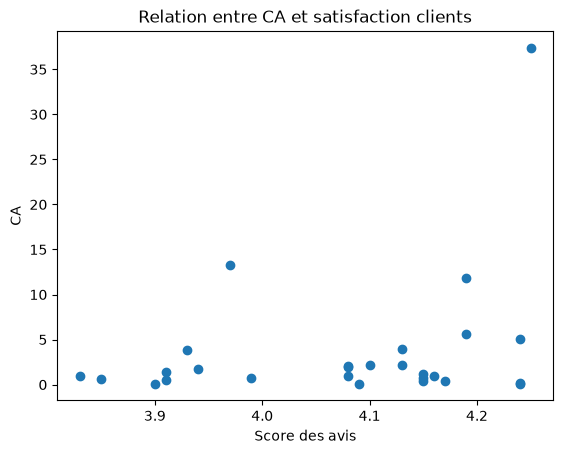

In [759]:
plt.scatter(etats['review_score'], etats['part_pct'])
plt.title("Relation entre CA et satisfaction clients")
plt.ylabel("CA")
plt.xlabel("Score des avis")
plt.show()

In [760]:
# 6. Croiser les missions 4 et 5
#    On peut étudier la satisfaction client en particulier dans les 5 états qui achètent le plus
livraisons_notes[livraisons_notes['customer_state'].isin(top5_state)].groupby('customer_state')['review_score'].mean()

customer_state
MG    4.192468
PR    4.239592
RJ    3.965141
RS    4.185599
SP    4.246519
Name: review_score, dtype: float64

---
## 🌉 Pont vers Power Query (à garder pour demain)

Ce que tu as fait aujourd'hui en pandas, tu le referas en Power Query, puis en SQL. Mêmes idées, autres outils.

| Opération | pandas | Power Query | SQL |
|---|---|---|---|
| Charger un fichier | `pd.read_csv()` | Obtenir les données › Texte/CSV | table importée |
| Convertir un type | `pd.to_datetime()`, `.astype()` | Modifier le type | `CAST(...)` |
| Filtrer des lignes | `df[df["col"] == "x"]` | Filtrer la colonne | `WHERE` |
| Joindre deux tables | `merge(how="left")` | Fusionner des requêtes (externe gauche) | `LEFT JOIN` |
| Remplacer les vides | `.fillna()` | Remplacer les valeurs | `COALESCE()` |
| Agréger | `groupby().agg()` | Regrouper par | `GROUP BY` |
| Grouper par mois | `.dt.to_period("M")` | Date › Mois, ou table de dates | `DATE_TRUNC('month', ...)` |
| Exporter | `.to_csv()` | Fermer et charger | — |